# Galaxy survey vs HI intensity mapping

*Runtime: about 13 s on a MacBook (Apple M2), full notebook.*

Two ways of mapping the same large-scale structure:

* **Galaxy survey**: detect individual galaxies and count them. Sharp positions, but limited by how many galaxies you can detect (shot noise).
* **HI intensity mapping**: measure the *total* 21cm emission in each pixel, without resolving galaxies. Fast and deep, but the map is smoothed by the telescope beam.

Here we use `meer21cm` to simulate **one** underlying density field over $0.4 < z < 0.6$, and observe it both ways on the same HEALPix sky patch.

In [1]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt

from meer21cm import MockSimulation
from meer21cm.plot import plot_map
from meer21cm.telescope import dish_beam_sigma
from meer21cm.util import redshift_to_freq

plt.rcParams.update({"font.size": 13})

## 1. Survey set-up

* Redshift $0.4 < z < 0.6$ $\Rightarrow$ 21cm observed at ~888–1015 MHz (MeerKAT UHF band).
* Sky patch: 80° in R.A. $\times$ 30° in Dec., HEALPix $N_{\rm side}=128$ (~0.46° pixels).
* Telescope beam: Gaussian beam of a 13.5 m MeerKAT dish, FWHM $\approx 1.2^\circ$–$1.4^\circ$ across the band.

In [2]:
z_min, z_max = 0.4, 0.6
nu = np.linspace(redshift_to_freq(z_max), redshift_to_freq(z_min), 64)  # Hz, 64 channels
nside = 128
ra_range = (140.0, 220.0)   # 80 deg
dec_range = (-30.0, 0.0)    # 30 deg
sigma_beam = dish_beam_sigma(13.5, nu)  # Gaussian beam sigma in deg, per channel

print(f"frequency: {nu.min()/1e6:.1f} - {nu.max()/1e6:.1f} MHz")
print(f"beam FWHM: {sigma_beam.min()*2.355:.2f} - {sigma_beam.max()*2.355:.2f} deg")

frequency: 887.8 - 1014.6 MHz
beam FWHM: 1.25 - 1.43 deg


## 2. One mock universe, two tracers

`MockSimulation` generates a lognormal matter density field in a box enclosing the light cone. From it we derive

* tracer 1: HI brightness temperature, $\bar{T}_{\rm HI}$ from $\Omega_{\rm HI}=5\times10^{-4}$, bias 1.5;
* tracer 2: galaxies, bias 1.9, Poisson-sampled into a catalogue with $\bar{n} = 3\times10^{-4}\,{\rm Mpc}^{-3}$.

Both come from the **same** density field (fixed `seed`), so the two maps should trace the same structures.

In [3]:
mock = MockSimulation(
    nu=nu,
    hp_nside=nside,
    ra_range=ra_range,
    dec_range=dec_range,
    sigma_beam_ch=sigma_beam,
    mean_amp_1="average_hi_temp",
    omega_hi=5e-4,
    tracer_bias_1=1.5,   # HI
    tracer_bias_2=1.9,   # galaxies
    downres_factor_transverse=0.5,  # simulation cells finer than the map pixels
    downres_factor_radial=0.5,
    seed=42,
)
n_gal = 3e-4  # Mpc^-3
mock.num_discrete_source = int(n_gal * mock.survey_volume)

print(f"{mock.pixel_id.size} HEALPix pixels, {mock.pixel_id.size * mock.pixel_area:.0f} deg^2")
print(f"survey volume: {mock.survey_volume/1e9:.2f} Gpc^3")

10782 HEALPix pixels, 2262 deg^2
survey volume: 1.78 Gpc^3


## 3. Observe it

* **HI**: project the HI field onto the sky pixels and smooth with the beam (`propagate_mock_field_to_data`).
* **Galaxies**: draw a galaxy catalogue (RA, Dec, z) from the galaxy field (`propagate_mock_tracer_to_gal_cat`), then count galaxies in each HEALPix pixel.

In [4]:
%%time
# HI intensity map: (n_pix, n_channel) cube in K, beam applied
hi_cube = mock.propagate_mock_field_to_data(mock.mock_tracer_field_1)

# galaxy catalogue -> mock.ra_gal, mock.dec_gal, mock.z_gal
mock.propagate_mock_tracer_to_gal_cat()
print(f"{mock.ra_gal.size} galaxies, z = {mock.z_gal.min():.3f} - {mock.z_gal.max():.3f}")

541852 galaxies, z = 0.399 - 0.602
CPU times: user 12 s, sys: 1.42 s, total: 13.4 s
Wall time: 8.74 s


In [5]:
# HI: average over all frequency channels, in mK
hi_map = hi_cube.mean(axis=-1) * 1e3

# galaxies: number counts in the same HEALPix pixels, summed over 0.4 < z < 0.6
gal_pix = hp.ang2pix(nside, mock.ra_gal, mock.dec_gal, lonlat=True)
gal_counts_full = np.bincount(gal_pix, minlength=hp.nside2npix(nside))
gal_map = gal_counts_full[mock.pixel_id]

print(f"mean galaxies per pixel: {gal_map.mean():.1f}")
print(f"correlation between the two maps: {np.corrcoef(hi_map, gal_map)[0, 1]:.2f}")

mean galaxies per pixel: 49.6
correlation between the two maps: 0.66


## 4. Compare

**(A)** HI intensity map: smooth, continuous, resolution set by the ~1° beam.  
**(B)** Galaxy survey: discrete counts per pixel, sharper but noisy (Poisson shot noise).

The same large-scale structures appear in both.

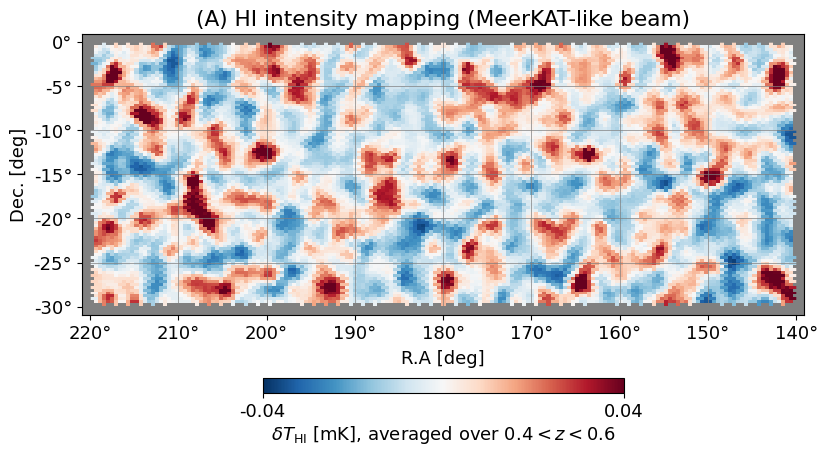

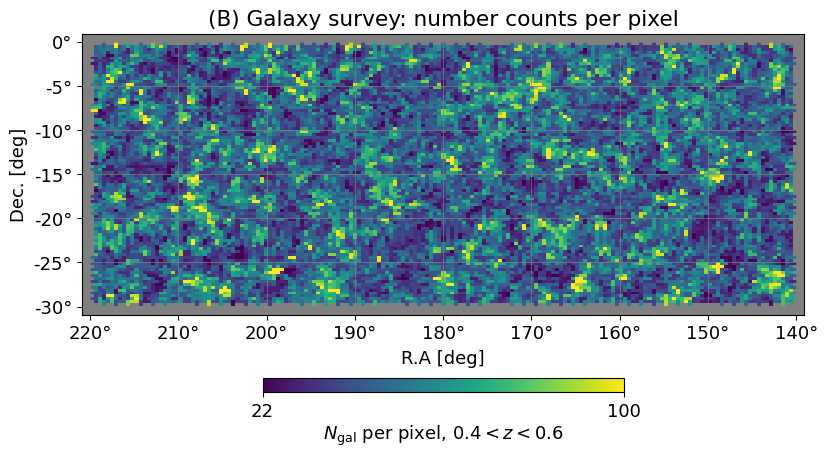

In [6]:
plot_kw = dict(pixel_id=mock.pixel_id, hp_nside=nside, ra_range=ra_range, dec_range=dec_range, dpi=100)

lim = float(f"{np.percentile(np.abs(hi_map), 99):.1g}")  # symmetric colour scale, rounded
plot_map(hi_map, cmap="RdBu_r", vmin=-lim, vmax=lim,
         title="(A) HI intensity mapping (MeerKAT-like beam)",
         cbar_label=r"$\delta T_{\rm HI}$ [mK], averaged over $0.4<z<0.6$", **plot_kw)
plt.savefig("hi_intensity_map.png", dpi=200, bbox_inches="tight")
plt.show()

plot_map(gal_map, cmap="viridis",
         vmin=np.percentile(gal_map, 1), vmax=np.percentile(gal_map, 99),
         title="(B) Galaxy survey: number counts per pixel",
         cbar_label=r"$N_{\rm gal}$ per pixel, $0.4<z<0.6$", **plot_kw)
plt.savefig("galaxy_count_map.png", dpi=200, bbox_inches="tight")
plt.show()

Combine the two panels into one slide-ready figure (`plot_map` draws HEALPix maps on their own figure, so we stack the saved images).

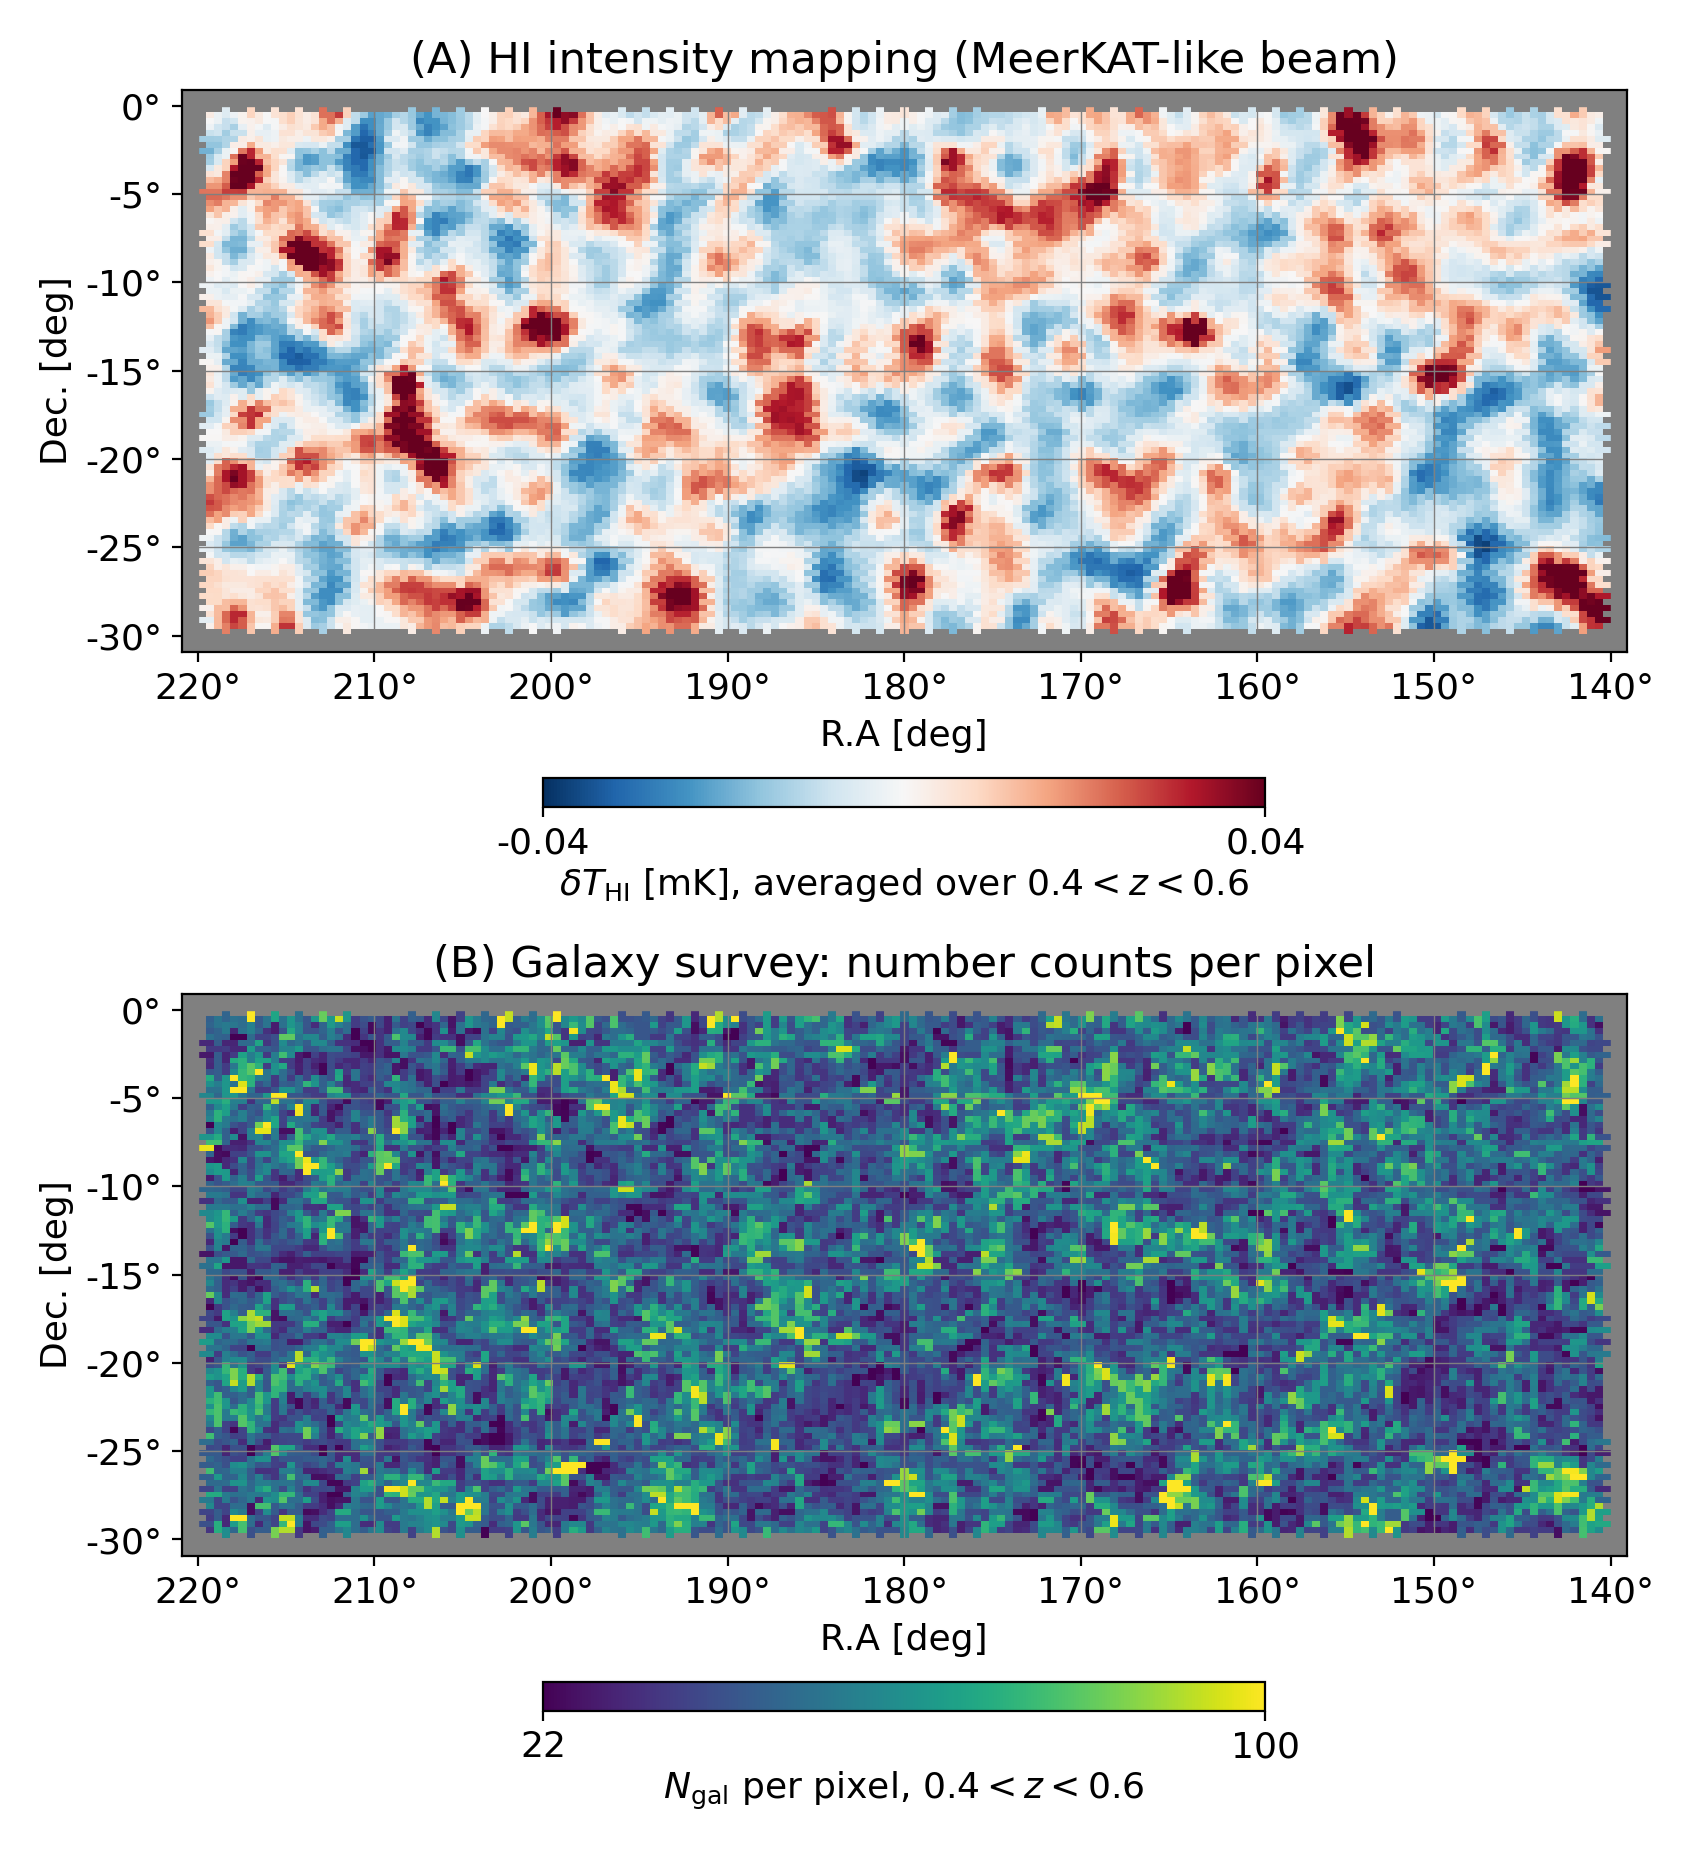

In [7]:
imgs = [plt.imread(f) for f in ["hi_intensity_map.png", "galaxy_count_map.png"]]
h = sum(im.shape[0] for im in imgs)
w = max(im.shape[1] for im in imgs)
fig = plt.figure(figsize=(w / 200, h / 200), dpi=200)
y0 = 1.0
for im in imgs:
    frac = im.shape[0] / h
    ax = fig.add_axes([0, y0 - frac, im.shape[1] / w, frac])
    ax.imshow(im)
    ax.axis("off")
    y0 -= frac
fig.savefig("hi_vs_galaxy_survey.png", dpi=200)
plt.show()